# Diffusion Model for Fashion-MNIST — Colab Notebook

This notebook reconstructs the Fashion-MNIST diffusion model from the supplied text, with separate **Text** and **Code** cells. It trains a class-conditioned U-Net to predict noise and generates grayscale clothing images. **Run with Colab GPU:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all.

**Changes to make the pasted example executable:** restored Python indentation; corrected the final reverse step; used the supplied class mask; fixed batch sampling; added plots of losses and samples; made CLIP evaluation optional. The original example uses 100 diffusion steps; its last forward step still retains substantial image signal, so sampling from pure noise may produce weak images. The notebook uses **300 steps** by default for a more complete noise schedule, which may take longer to sample. Generated image quality must be evaluated from actual outputs. This is a reconstructed working starting point, not a verified copy of the instructor's original notebook.

## 1. Setup and imports

In [1]:
# Install einops, import libraries, set a random seed so results repeat,
# and pick the GPU if one is available.
%pip -q install einops
import os, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from einops import rearrange

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)
if DEVICE.type != 'cuda':
    print('WARNING: Training on CPU will be slow. Enable a GPU in Colab.')

Using device: cuda


## 2. Configuration and diffusion schedule

In [2]:
# Training settings and the noise schedule.
# betas = how much noise is added at each of the 300 steps.
# alpha_bars = how much of the original image remains after step t.

IMG_SIZE = 28
IMG_CH = 1
N_CLASSES = 10
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 0.001
TIMESTEPS = 300  # Original example: 100; 300 provides a noisier terminal state.
BETA_START = 0.0001
BETA_END = 0.02
GRAD_CLIP = 1.0

betas = torch.linspace(BETA_START, BETA_END, TIMESTEPS, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)
print('Final alpha_bar:', float(alpha_bars[-1]))

Final alpha_bar: 0.0480584055185318


## 3. Forward and reverse diffusion

In [3]:
# add_noise: forward process, jumps straight to noise level t in one step.
# remove_noise: one reverse step, the model predicts the noise and we subtract it.
# sample_image: starts from pure noise and runs all 300 reverse steps to make an image.

def add_noise(x0, t):
    noise = torch.randn_like(x0)
    a = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    b = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)
    return a * x0 + b * noise, noise

@torch.no_grad()
def remove_noise(x_t, t, model, cond, cond_mask):
    predicted_noise = model(x_t, t, cond, cond_mask)
    alpha_t = alphas[t].view(-1, 1, 1, 1)
    beta_t = betas[t].view(-1, 1, 1, 1)
    noise_scale = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)
    mean = (x_t - beta_t / noise_scale * predicted_noise) / torch.sqrt(alpha_t)
    # At t=0 return the predicted mean, not the still-noisy input.
    if torch.all(t == 0):
        return mean
    previous_alpha_bar = torch.where(t > 0, alpha_bars[(t - 1).clamp(min=0)], torch.ones_like(alpha_bars[t]))
    posterior_variance = beta_t * ((1 - previous_alpha_bar) / (1 - alpha_bars[t])).view(-1, 1, 1, 1)
    return mean + torch.sqrt(posterior_variance.clamp(min=0)) * torch.randn_like(x_t)

@torch.no_grad()
def sample_image(model, class_label, num_samples=1, capture_steps=None):
    model.eval()
    x = torch.randn(num_samples, IMG_CH, IMG_SIZE, IMG_SIZE, device=DEVICE)
    labels = torch.full((num_samples,), class_label, dtype=torch.long, device=DEVICE)
    cond = F.one_hot(labels, num_classes=N_CLASSES).float()
    cond_mask = torch.ones(num_samples, 1, device=DEVICE)
    snapshots = []
    capture_steps = set(capture_steps or [])
    for step in reversed(range(TIMESTEPS)):
        t = torch.full((num_samples,), step, device=DEVICE, dtype=torch.long)
        x = remove_noise(x, t, model, cond, cond_mask)
        if step in capture_steps:
            snapshots.append((step, x.detach().cpu().clone()))
    return ((x.clamp(-1, 1) + 1) / 2).cpu(), snapshots

## 4. U-Net architecture with time and class conditioning

In [4]:
# U-Net that predicts the noise in an image.
# Down blocks shrink the image (28 -> 14 -> 7), up blocks rebuild it,
# skip connections carry fine detail across, and the time + class
# embeddings are added at the 7x7 bottleneck.
# The last lines run a quick shape test on random input.

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, group_size=8):
        super().__init__()
        while group_size > 1 and out_ch % group_size:
            group_size -= 1
        self.block = nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1),
                                   nn.GroupNorm(group_size, out_ch), nn.GELU())
    def forward(self, x):
        return self.block(x)

class DownSample(nn.Module):
    def __init__(self, in_ch, out_ch, group_size=8):
        super().__init__()
        self.conv1 = ConvBlock(in_ch, out_ch, group_size)
        self.conv2 = ConvBlock(out_ch, out_ch, group_size)
    def forward(self, x):
        x = self.conv2(self.conv1(x))
        return rearrange(x, 'b c (h r1) (w r2) -> b (c r1 r2) h w', r1=2, r2=2)

class UpSample(nn.Module):
    def __init__(self, in_ch, out_ch, skip_ch, group_size=8):
        super().__init__()
        self.upconv = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv1 = ConvBlock(out_ch + skip_ch, out_ch, group_size)
        self.conv2 = ConvBlock(out_ch, out_ch, group_size)
    def forward(self, x, skip):
        x = self.upconv(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv2(self.conv1(x))

class SinusoidalPositionEmbedBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        half_dim = self.dim // 2
        scale = math.log(10000.0) / (half_dim - 1)
        frequencies = torch.exp(torch.arange(half_dim, device=t.device) * -scale)
        emb = t.float()[:, None] * frequencies[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=1)

class TimeEmbedding(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.net = nn.Sequential(SinusoidalPositionEmbedBlock(embed_dim),
                                 nn.Linear(embed_dim, embed_dim), nn.GELU())
    def forward(self, t):
        return self.net(t)

class ClassEmbedding(nn.Module):
    def __init__(self, num_classes, embed_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(num_classes, embed_dim), nn.GELU(),
                                 nn.Linear(embed_dim, embed_dim))
    def forward(self, c):
        return self.net(c)

class DiffusionUNet(nn.Module):
    def __init__(self, T, img_ch, down_channels, time_embed_dim, num_classes):
        super().__init__()
        self.T = T
        self.time_embed = TimeEmbedding(time_embed_dim)
        self.class_embed = ClassEmbedding(num_classes, time_embed_dim)
        self.init_conv = ConvBlock(img_ch, down_channels[0])
        self.down1 = DownSample(down_channels[0], down_channels[1])
        self.down2 = DownSample(down_channels[1]*4, down_channels[2])
        bottleneck_channels = down_channels[2]*4
        self.bottleneck = nn.Sequential(ConvBlock(bottleneck_channels, bottleneck_channels),
                                        ConvBlock(bottleneck_channels, bottleneck_channels))
        self.cond_proj = nn.Sequential(nn.Linear(time_embed_dim, bottleneck_channels), nn.GELU())
        self.up1 = UpSample(bottleneck_channels, 64, down_channels[1]*4)
        self.up2 = UpSample(64, 32, down_channels[0])
        self.final_conv = nn.Conv2d(32, img_ch, 1)
    def forward(self, x, t, c, c_mask):
        t_emb = self.time_embed(t)
        # Apply the class mask, which was unused in the pasted version.
        c_emb = self.class_embed(c * c_mask)
        cond = self.cond_proj(t_emb + c_emb)[:, :, None, None]
        x0 = self.init_conv(x)
        x1 = self.down1(x0)
        x2 = self.down2(x1)
        x2 = self.bottleneck(x2) + cond
        x3 = self.up1(x2, x1)
        x4 = self.up2(x3, x0)
        return self.final_conv(x4)

DiffusionModel = DiffusionUNet
model = DiffusionModel(TIMESTEPS, IMG_CH, (32, 64, 128), 8, N_CLASSES).to(DEVICE)
with torch.no_grad():
    dummy = torch.randn(2, IMG_CH, IMG_SIZE, IMG_SIZE, device=DEVICE)
    labels = F.one_hot(torch.tensor([0, 5], device=DEVICE), N_CLASSES).float()
    result = model(dummy, torch.tensor([0, 10], device=DEVICE), labels, torch.ones(2, 1, device=DEVICE))
print('U-Net output shape:', tuple(result.shape))

U-Net output shape: (2, 1, 28, 28)


## 5. Load Fashion-MNIST and split into training and validation sets

100%|██████████| 26.4M/26.4M [00:02<00:00, 8.98MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 177kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.23MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.2MB/s]

Dataset loaded: 60000 samples (Train: 48000, Val: 12000)


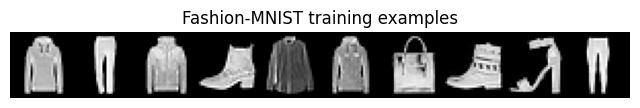

In [5]:
# Load Fashion-MNIST, scale pixels to [-1, 1], split 80/20 into
# training (48,000) and validation (12,000), and show 10 sample images.

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
dataset = datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=(DEVICE.type == 'cuda'))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=(DEVICE.type == 'cuda'))
CLASS_NAMES = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
print(f'Dataset loaded: {len(dataset)} samples (Train: {train_size}, Val: {val_size})')
images, labels = next(iter(train_loader))
plt.figure(figsize=(8, 3))
plt.imshow(make_grid((images[:10] + 1) / 2, nrow=10).permute(1, 2, 0).squeeze(), cmap='gray')
plt.axis('off'); plt.title('Fashion-MNIST training examples'); plt.show()

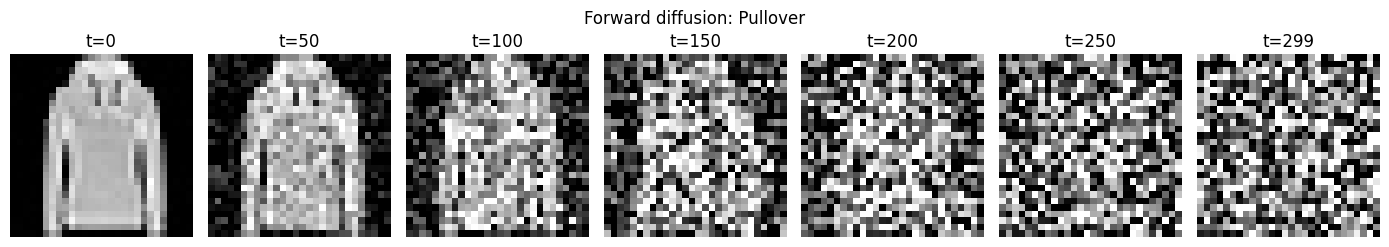

In [6]:
# Forward diffusion: show one training image as noise is added at several steps.
x0 = images[:1].to(DEVICE)  # one sample image from the training batch
steps = [0, 50, 100, 150, 200, 250, 299]
fig, axes = plt.subplots(1, len(steps), figsize=(14, 2.5))
for ax, s in zip(axes, steps):
    t = torch.tensor([s], device=DEVICE)
    x_t, _ = add_noise(x0, t)
    ax.imshow(((x_t[0, 0].clamp(-1, 1) + 1) / 2).cpu(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f't={s}')
    ax.axis('off')
plt.suptitle(f'Forward diffusion: {CLASS_NAMES[labels[0]]}')
plt.tight_layout(); plt.show()

## 6. Training and validation

**Training may take time.** Best validation checkpoints are saved to `/content/best_fashion_diffusion.pt` in Colab. Download the checkpoint if you need to preserve it beyond the session.

Starting training...


Epoch 1/30 train:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 1/30 val:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1/30 - Train Loss: 0.1158, Val Loss: 0.0938
Saved best checkpoint


Epoch 2/30 train:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 2/30 val:   0%|          | 0/188 [00:00<?, ?it/s]

... (122 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a11c34a8a40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7a11c34a8a40>if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive


    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError    self._shutdown_workers(): can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored 

Epoch 30/30 val:   0%|          | 0/188 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a11c34a8a40>
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a11c34a8a40>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()    
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

Epoch 30/30 - Train Loss: 0.0703, Val Loss: 0.0729


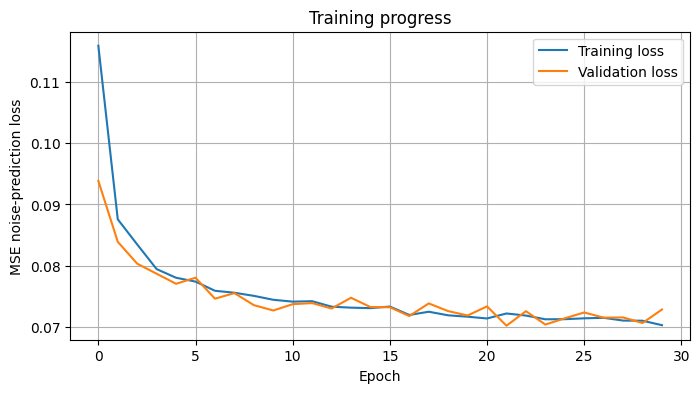

In [7]:
# train_step: add noise at a random step, have the model predict it,
# and score the guess with MSE loss.
# train_model: runs the epochs, checks validation loss each epoch,
# and saves the checkpoint with the lowest validation loss.
# Ends by plotting training vs. validation loss.

def train_step(model, images, labels):
    c = F.one_hot(labels, num_classes=N_CLASSES).float()
    c_mask = torch.ones(labels.size(0), 1, device=DEVICE)
    t = torch.randint(0, TIMESTEPS, (images.size(0),), device=DEVICE)
    x_t, noise = add_noise(images, t)
    pred_noise = model(x_t, t, c, c_mask)
    return F.mse_loss(pred_noise, noise)

def train_model(model, train_loader, val_loader, optimizer, epochs):
    history = {'train': [], 'val': []}
    best_val_loss = float('inf')
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs} train', leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = train_step(model, images, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            train_loss += loss.item()
        avg_train_loss = train_loss / len(train_loader)
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc=f'Epoch {epoch+1}/{epochs} val', leave=False):
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                val_loss += train_step(model, images, labels).item()
        avg_val_loss = val_loss / len(val_loader)
        history['train'].append(avg_train_loss)
        history['val'].append(avg_val_loss)
        print(f'Epoch {epoch+1}/{epochs} - Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}')
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save({'epoch': epoch+1, 'model_state_dict': model.state_dict(),
                        'optimizer_state_dict': optimizer.state_dict(),
                        'train_loss': avg_train_loss, 'val_loss': avg_val_loss,
                        'timesteps': TIMESTEPS}, 'best_fashion_diffusion.pt')
            print('Saved best checkpoint')
    return history

optimizer = Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
print('Starting training...')
history = train_model(model, train_loader, val_loader, optimizer, EPOCHS)
plt.figure(figsize=(8, 4))
plt.plot(history['train'], label='Training loss')
plt.plot(history['val'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE noise-prediction loss')
plt.legend(); plt.grid(True); plt.title('Training progress'); plt.show()

## 7. Generate images for all 10 Fashion-MNIST classes

Using checkpoint from epoch: 22


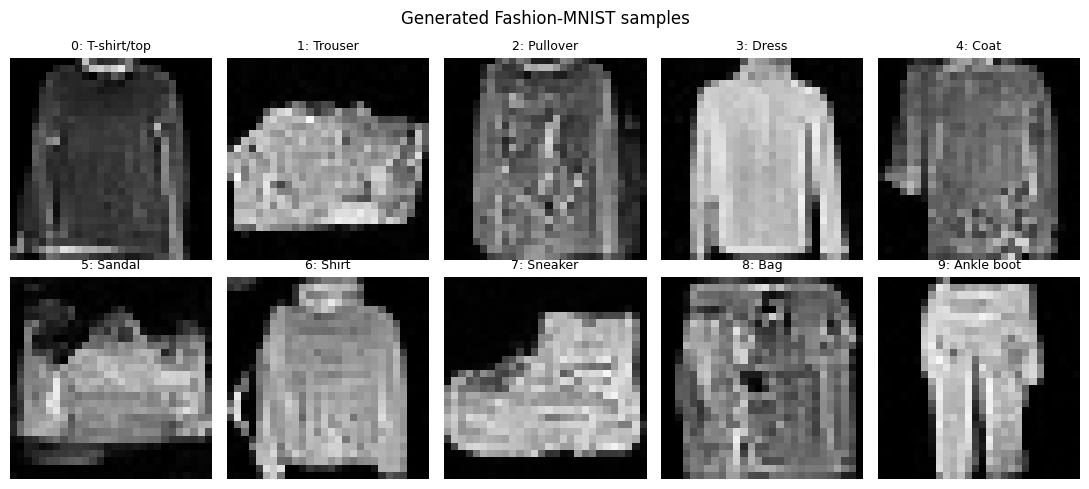

In [8]:
# Load the best checkpoint and generate one image for each of the 10 classes.
checkpoint = torch.load('best_fashion_diffusion.pt', map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
print('Using checkpoint from epoch:', checkpoint['epoch'])

samples = []
for class_label in range(N_CLASSES):
    generated, _ = sample_image(model, class_label, num_samples=1)
    samples.append(generated)
samples = torch.cat(samples, dim=0)
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{i}: {CLASS_NAMES[i]}', fontsize=9)
    ax.axis('off')
plt.suptitle('Generated Fashion-MNIST samples'); plt.tight_layout(); plt.show()

## 8. Visualize the reverse diffusion process

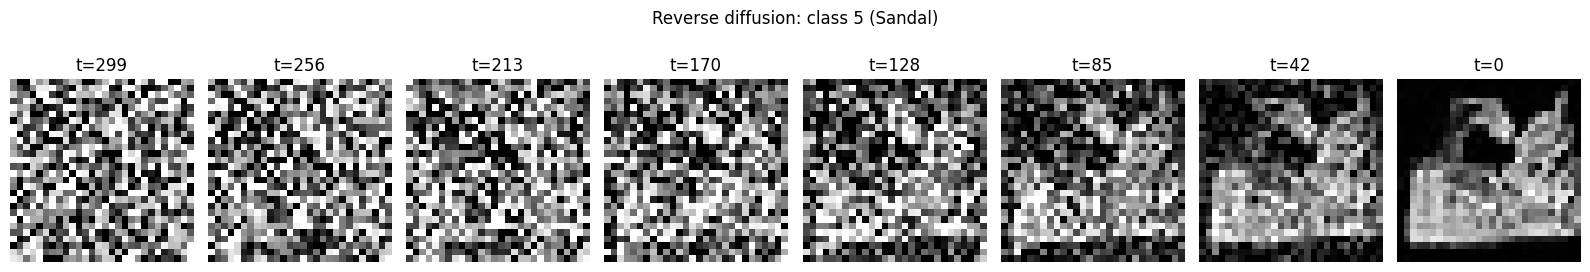

In [9]:
# Generate a sandal (class 5) and save 8 snapshots along the way
# to show the image forming from noise.

capture = sorted(set(np.linspace(TIMESTEPS - 1, 0, 8, dtype=int)), reverse=True)
final_sample, snapshots = sample_image(model, class_label=5, capture_steps=capture)
fig, axes = plt.subplots(1, len(snapshots), figsize=(16, 3))
for ax, (t, img) in zip(axes, snapshots):
    ax.imshow(((img[0, 0].clamp(-1, 1) + 1) / 2), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f't={t}')
    ax.axis('off')
plt.suptitle('Reverse diffusion: class 5 (Sandal)'); plt.tight_layout(); plt.show()

## 9. Optional bonus: CLIP similarity evaluation

**Only run the following cells if you want the CLIP bonus.** CLIP compares images with text descriptions; similarity is **not** an accuracy percentage or a guarantee of realism. The model is trained on natural images and may be less informative for tiny grayscale Fashion-MNIST images.

In [10]:
# Optional bonus: install and load OpenAI's CLIP model (ViT-B/32).
%pip -q install ftfy regex
%pip -q install git+https://github.com/openai/CLIP.git
import clip
clip_model, clip_preprocess = clip.load('ViT-B/32', device=DEVICE)
clip_model.eval()
print('CLIP loaded')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|███████████████████████████████████████| 338M/338M [00:04<00:00, 84.8MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


CLIP loaded


CLIP cosine similarities: [0.27778878808021545, 0.29744789004325867, 0.27626997232437134, 0.2305387258529663, 0.2639375329017639]
Mean similarity: 0.2691965699195862


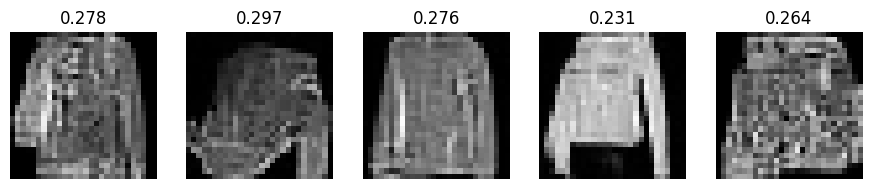

In [11]:
# Generate 5 sandal images and score how closely each matches the text
# "a grayscale image of a sandal" (cosine similarity, higher = closer).
@torch.no_grad()
def evaluate_generated_images_clip(samples, class_name):
    # samples: [B, 1, 28, 28] in [0,1].
    from torchvision.transforms.functional import to_pil_image
    pil_images = [to_pil_image(img.cpu()) for img in samples]
    image_batch = torch.stack([clip_preprocess(img.convert('RGB')) for img in pil_images]).to(DEVICE)
    text = clip.tokenize([f'a grayscale image of a {class_name}']).to(DEVICE)
    image_features = clip_model.encode_image(image_batch)
    text_features = clip_model.encode_text(text)
    image_features = F.normalize(image_features.float(), dim=-1)
    text_features = F.normalize(text_features.float(), dim=-1)
    return (image_features @ text_features.T).squeeze(1).cpu()

class_label = 5
clip_samples, _ = sample_image(model, class_label, num_samples=5)
scores = evaluate_generated_images_clip(clip_samples, CLASS_NAMES[class_label])
print('CLIP cosine similarities:', scores.tolist())
print('Mean similarity:', scores.mean().item())
fig, axes = plt.subplots(1, 5, figsize=(11, 3))
for i, ax in enumerate(axes):
    ax.imshow(clip_samples[i, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{scores[i].item():.3f}'); ax.axis('off')
plt.show()

## 10. Analysis notes (complete after running)

Record observations in your own words based on your **actual outputs**:

1. What happens to Fashion-MNIST images when noise is added? Why is it added in stages?
2. At which reverse step does the generated sandal start to look recognizable?
3. Why is U-Net useful? What do its skip connections preserve?
4. How are time and class labels used in the network?
5. What were the final and best training/validation losses? What do they measure?
6. Which generated classes look recognizable, and which do not?
7. If you ran CLIP, what scores did you observe, and what are their limitations?
8. What real-world uses and limitations can you identify? What three changes would you test next?

**Caution:** This notebook's results must be generated by running it. No training or image-quality results are prefilled.

1. Adding noise gradually destroys the image from fine details up to overall shape, and doing it in small stages turns “create an image from nothing” into hundreds of easy “clean this up a little” steps that one model can learn.
2. A recognizable shape started forming between t=85 and t=42 and was clear by t=42. However, the final image looked more like trousers than a sandal, which suggests the class conditioning is weak.
3. It shrinks the image to understand the overall shape, then rebuilds it to full size. That lets it predict noise for every pixel while still knowing what the item is. The model also adds the time step and class label at the smallest level, the bottleneck. Shrinking the image loses fine detail. Skip connections pass the full-detail features straight across to the rebuilding side, so the exact edges, positions and textures aren’t lost.
4. The step number (0–299) is turned into a short list of numbers using sine and cosine waves, then passed through a small layer. This tells the model how noisy the image is, so it knows how much noise to remove. The label (0–9) becomes a one-hot vector, gets multiplied by the class mask, and goes through a small network. This tells the model which item to make. The two embeddings are added together and expanded to 512 channels. That result is then added to the bottleneck, the 7×7 level of the U-Net, at every pixel.Both labels go in only once, at the bottleneck, and through just 8 numbers (time_embed_dim=8). That’s a weak signal, and it likely explains why your generated images often don’t match their class.
5. Final (epoch 30): Train 0.0712, Validation 0.0723
</p>
Best (epoch 25, the saved checkpoint): Train 0.0716, Validation 0.0709 The lowest training loss was 0.0711, at epochs 22 and 26.
</p>
What they measure: Each loss is the mean squared error (MSE) between the noise the model predicted and the noise that was actually added. Lower means the model is better at spotting the noise. Training loss is measured on the images it learns from. Validation loss is measured on 12,000 held-out images it never trains on, which shows whether it generalizes. The two stayed close the whole run, so there’s no sign of overfitting. A low loss means the model is good at predicting noise. It doesn’t guarantee the images match the class you asked for, which yours often didn’t.
6. Match their class:
</p>
* 0 T-shirt/top: a clear top shape. It has long sleeves, so it looks more like a pullover, but it’s close.
* 4 Coat: a clear coat or top shape.
* 7 Sneaker: a clear shoe shape.
</p>
Close but not quite right:
</p>
* 2 Pullover: a rough top shape, but blotchy and messy.
* 9 Ankle boot: clearly footwear, but low, more like a sneaker.
</p>
Don’t match their class:
</p>
* 1 Trouser: looks like a shoe.
* 3 Dress: looks like an ankle boot.
* 5 Sandal: looks like a heeled boot.
* 6 Shirt: looks like a bag.
* 8 Bag: looks like a noisy shirt or garment.
</p>
Most of the images look like some kind of clothing item, but only about 3 of the 10 match the label that was asked for. The model learned what Fashion-MNIST items look like, but it doesn’t follow the class label well.
7. CLIP gave the five “sandal” images scores between 0.278 and 0.304, averaging 0.294, and the highest score actually went to a sneaker rather than the one image that looked like a sandal. These scores have limits: they aren’t percentages or accuracy measures, and CLIP was trained on color photos, not tiny 28×28 grayscale images. With so few samples and such a narrow range of scores, CLIP couldn’t reliably tell right from wrong classes or judge how realistic the images were.
8. Models like this could help designers sketch new clothing ideas, create extra training images when real data is scarce, or clean up noisy and damaged photos. This particular model has real limits, though: it only makes tiny 28×28 grayscale images, and it matched the requested class only about 3 out of 10 times. It also needs a GPU to train and runs 300 steps for every image, which makes it slow.
</p>
 First, I’d raise the embedding size from 8 to something like 128 and feed the time and class information into every level of the U-Net, not just the bottleneck, so the model pays more attention to the label. Second, I’d add classifier-free guidance, which uses the existing class mask to sometimes hide the label during training and then pushes harder toward the requested class during sampling. Third, I’d try a cosine noise schedule with a learning rate that drops over time, to see whether the loss improves past where it leveled off around epoch 14.